# SICOR Cerrado — correção de UF, finalidade e integração financeira

**Versão 2 — preparada para seus arquivos do Drive em 16/09/2026.**

Este notebook gera uma **nova base**, mantendo todas as linhas e geometrias da Base04. Corrige UF, recupera finalidade e instrumento, vincula liberações e desclassificações e examina o histórico mensal de saldos por **REF_BACEN + NU_ORDEM**. Produz tabelas e gráficos para revisar a seção 5.2.1.

### Como executar
1. Abra este `.ipynb` no Google Colab.
2. Confira a **data de corte** e os caminhos na célula 2. Os caminhos já correspondem às pastas localizadas no seu Drive, inclusive `Base/Novos`.
3. Use **Ambiente de execução → Executar tudo** e autorize a montagem do Drive.
4. Aguarde o processamento. Não é necessário GPU. Os arquivos nacionais somam vários GB; a leitura é feita em blocos, com progresso a cada 10 blocos.
5. Ao terminar, abra a nova pasta de resultados cujo caminho será mostrado na última célula. Para revisão do texto, compartilhe essa pasta ou `resumo_graficos.zip`.

**Unidades:** a base territorial permanece com todas as linhas; a tabela financeira tem uma linha por ordem territorial; as contagens de operações usam referências distintas. Resultados financeiros não abrangem automaticamente ordens da mesma operação que estejam fora da Base04.

**Limite de interpretação:** situação “Liquidada” é informação administrativa na última observação encontrada. Ausência de liberação localizada e exclusão são apresentadas como evidências para verificação, sem comprovar automaticamente cancelamento anterior ao desembolso.

Fonte dos campos: [Manual de dados do SICOR, versão 6 — Banco Central](https://www.bcb.gov.br/htms/sicor/manualDadosSicor_V6.pdf).


In [3]:
# 1. Montar o Google Drive e importar bibliotecas
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
from datetime import datetime
import json, zipfile, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print('Ambiente preparado. GPU não é necessária.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ambiente preparado. GPU não é necessária.


## 2. Caminhos e data de corte

O período de **emissão** da base é 2021–2025. O acompanhamento financeiro pode avançar além de 2025. O corte abaixo é **16/09/2026**, data dos arquivos novos. Se desejar analisar apenas acontecimentos até 31/12/2025, altere `DATA_CORTE`.

Para saldos mensais, utiliza-se o último **mês completo** até o corte (agosto de 2026 no padrão). Se os arquivos não alcançarem esse mês, o resultado informa a última observação disponível e não a transporta automaticamente para o corte.

Os arquivos `SICOR_SALDOS_2021` a `2025` são todos lidos: a referência temporal é extraída de `ANO_BASE` e `MES_BASE`, sem inferir o período pelo nome. As cópias antigas de saldos não são adicionadas, para evitar sobreposição entre versões.


In [4]:
# 2. Configuração — altere apenas se seus arquivos foram movidos
DATA_CORTE = '2026-09-16'
TAMANHO_BLOCO = 100_000  # Reduza para 50_000 se faltar memória.
RAIZ_ENVIO = Path('/content/drive/MyDrive/Colab Notebooks/fluxo/Envio')
PASTA_BASE = RAIZ_ENVIO / 'Base'
PASTA_NOVOS = PASTA_BASE / 'Novos'
PASTA_BASE04 = RAIZ_ENVIO / 'Arquivos gerados e relatorios' / 'Base04_enriquecimento_detalhado'
PASTA_DOMINIOS = Path('/content/drive/MyDrive/Colab Notebooks/project/sicor_preparacao/dados_bcb')
PASTA_OUTROS = Path('/content/drive/MyDrive/Colab Notebooks/outros')

CAMINHOS = {
 'base': PASTA_BASE04 / 'sicor_cerrado_2021_2025_enriquecido_detalhado_com_id_gleba2.csv',
 'operacoes': [PASTA_BASE / f'SICOR_OPERACAO_BASICA_ESTADO_{ano}.csv' for ano in range(2021,2026)],
 'empreendimento': PASTA_DOMINIOS / 'Empreendimento.csv',
 'instrumento': PASTA_DOMINIOS / 'InstrumentoCredito.csv',
 'situacao': PASTA_OUTROS / 'SituacaoOperacao.csv',
 'motivo': PASTA_OUTROS / 'motivoDesclassificacao.csv',
 'liberacoes': PASTA_NOVOS / 'SICOR_LIBERACAO_RECURSOS.csv',
 'desclassificacoes': PASTA_NOVOS / 'sicor_desclassificacao.csv',
 'saldos': [PASTA_NOVOS / f'SICOR_SALDOS_{ano}.csv' for ano in range(2021,2026)],
}
# AUTO identifica ISO ou a ordem de dia/mês por datas não ambíguas.
# O arquivo novo de desclassificação foi conferido: usa mês/dia/ano (MDY).
FORMATOS_DATAS = {'base':'AUTO', 'liberacoes':'AUTO', 'desclassificacoes':'MDY'}

CORTE = pd.Timestamp(DATA_CORTE).normalize()
EXECUCAO = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
SAIDA = PASTA_BASE04 / 'correcao_uf_finalidade_financeiro' / EXECUCAO

def resolver_arquivo(p):
    if p.exists(): return p
    # Aceita extensão .gz e diferenças de maiúsculas, sem escolher entre duplicatas.
    if p.parent.exists():
        encontrados=[f for f in p.parent.iterdir() if f.is_file() and f.name.casefold() in {p.name.casefold(),p.name.casefold()+'.gz'}]
        if len(encontrados)==1: return encontrados[0]
    raise FileNotFoundError(f'Arquivo não encontrado: {p}. Ajuste o caminho na célula 2.')

for k,v in CAMINHOS.items():
    CAMINHOS[k]=[resolver_arquivo(p) for p in v] if isinstance(v,list) else resolver_arquivo(v)
SAIDA.mkdir(parents=True,exist_ok=False)
manifesto=[]
for k,v in CAMINHOS.items():
    for p in v if isinstance(v,list) else [v]:
        manifesto.append({'grupo':k,'arquivo':str(p),'bytes':p.stat().st_size,'modificacao_local':datetime.fromtimestamp(p.stat().st_mtime).isoformat()})
pd.DataFrame(manifesto).to_csv(SAIDA/'inventario_entradas.csv',sep=';',index=False,encoding='utf-8-sig')
(SAIDA/'configuracao.json').write_text(json.dumps({'data_corte':DATA_CORTE,'execucao':EXECUCAO,'formatos_datas':FORMATOS_DATAS,'caminhos':{k:[str(p) for p in v] if isinstance(v,list) else str(v) for k,v in CAMINHOS.items()}},ensure_ascii=False,indent=2),encoding='utf-8')
print('Entradas encontradas. Resultados serão salvos em:',SAIDA)


Entradas encontradas. Resultados serão salvos em: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/Base04_enriquecimento_detalhado/correcao_uf_finalidade_financeiro/20260917_020231_695319


### Funções — funções de leitura e validação

In [5]:
import csv, gzip, io, json, re, sqlite3, unicodedata, gc, time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

LOG = []
SCHEMAS = {}

def normal(s):
    s = ''.join(c for c in unicodedata.normalize('NFKD', str(s)) if not unicodedata.combining(c))
    return re.sub(r'[^A-Z0-9]+', '_', s.upper()).strip('_')

def texto(s):
    return s.astype('string').str.strip().replace({'':pd.NA,'nan':pd.NA,'None':pd.NA,'<NA>':pd.NA})

def codigo(s):
    x = texto(s).str.replace(r'\.0+$','',regex=True)
    return x.str.replace(r'^0+(?=\d)','',regex=True)

def numero(s):
    x = texto(s).str.replace('R$', '', regex=False).str.replace(' ', '', regex=False)
    comma = x.str.contains(',',na=False)
    x = x.where(~comma, x.str.replace('.', '', regex=False).str.replace(',', '.', regex=False))
    return pd.to_numeric(x, errors='coerce').astype('Float64')

UF_IBGE = dict(zip('11 12 13 14 15 16 17 21 22 23 24 25 26 27 28 29 31 32 33 35 41 42 43 50 51 52 53'.split(),
                       'RO AC AM RR PA AP TO MA PI CE RN PB PE AL SE BA MG ES RJ SP PR SC RS MS MT GO DF'.split()))
def uf(s):
    x = codigo(s).str.upper()
    return x.where(x.isin(UF_IBGE.values()), x.map(UF_IBGE)).astype('string')

def estrutura(path):
    path = Path(path)
    if str(path) in SCHEMAS: return SCHEMAS[str(path)]
    opener = gzip.open if path.suffix.lower()=='.gz' else open
    with opener(path, 'rb') as f: sample = f.read(256_000)
    for enc in ['utf-8-sig','cp1252','latin1']:
        try: raw = sample.decode(enc); break
        except UnicodeDecodeError: pass
    line = next(l for l in raw.splitlines() if l.strip())
    delim = max([';',',','\t','|'], key=lambda d: len(next(csv.reader([line],delimiter=d))))
    names = next(csv.reader([line], delimiter=delim))
    names_norm = [normal(n) for n in names]
    if len(names_norm)!=len(set(names_norm)): raise ValueError(f'Cabeçalhos duplicados: {path}')
    ans = (enc,delim,dict(zip(names_norm,names)),raw)
    SCHEMAS[str(path)] = ans
    return ans

def blocos(path, required=(), optional=(), chunk=100_000):
    enc,sep,mapping,_ = estrutura(path)
    missing=set(required)-set(mapping)
    if missing: raise ValueError(f'{Path(path).name}: faltam {sorted(missing)}. Colunas: {list(mapping)}')
    chosen=list(dict.fromkeys([*required,*optional]))
    use=[mapping[c] for c in chosen if c in mapping] if chosen else None
    for b in pd.read_csv(path,sep=sep,encoding=enc,dtype='string',usecols=use,chunksize=chunk,keep_default_na=False):
        b.columns=[normal(c) for c in b.columns]
        for c in b: b[c]=texto(b[c])
        yield b

def pequeno(path):
    enc,sep,_,_=estrutura(path)
    # Corrige a representação encontrada em SituacaoOperacao.csv:
    # cabeçalho com duas colunas e cada linha inteira entre aspas.
    opener=gzip.open if str(path).endswith('.gz') else open
    with opener(path,'rt',encoding=enc,newline='') as f:
        rows=list(csv.reader(f,delimiter=sep))
    head=rows[0]; clean=[]
    for row in rows[1:]:
        if not row: continue
        if len(row)==1 and len(head)>1: row=next(csv.reader([row[0]],delimiter=sep))
        if len(row)!=len(head): raise ValueError(f'Domínio malformado em {path}: {row}')
        clean.append(row)
    return pd.DataFrame(clean,columns=[normal(c) for c in head]).astype('string').replace('',pd.NA)

def ordem(b, col='NU_ORDEM'):
    return codigo(b['REF_BACEN']) + '|' + codigo(b[col])

def modo_data(path, col, escolha='AUTO'):
    if escolha!='AUTO': return escolha
    sample=pd.concat([b for _,b in zip(range(2),blocos(path,required=[col],chunk=10000))],ignore_index=True)[col]
    parts=sample.str.extract(r'^(\d{1,2})/(\d{1,2})/(\d{4})')
    a=pd.to_numeric(parts[0],errors='coerce'); b=pd.to_numeric(parts[1],errors='coerce')
    dmy=(a>12).any(); mdy=(b>12).any()
    if dmy and mdy: raise ValueError(f'Datas DMY/MDY misturadas em {path}; confira a origem.')
    if dmy: return 'DMY'
    if mdy: return 'MDY'
    if parts[0].notna().any():
        raise ValueError(f'Datas ambíguas em {Path(path).name}. Defina DMY ou MDY em FORMATOS_DATAS e execute novamente.')
    return 'ISO'

def datas(s, modo):
    x=texto(s)
    out=pd.Series(pd.NaT,index=s.index,dtype='datetime64[ns]')
    iso=x.str.match(r'^\d{4}-\d{2}-\d{2}',na=False)
    out.loc[iso]=pd.to_datetime(x.loc[iso].str.slice(0,10),format='%Y-%m-%d',errors='coerce')
    fmt={'DMY':'%d/%m/%Y','MDY':'%m/%d/%Y','ISO':'%Y-%m-%d'}[modo]
    out.loc[~iso]=pd.to_datetime(x.loc[~iso].str.slice(0,10),format=fmt,errors='coerce')
    return out

def salvar(df,path):
    df.to_csv(path,index=False,sep=';',encoding='utf-8-sig',decimal=',')

def unico_por_chave(df, cols, label, saida):
    counts=df.groupby('CHAVE')[cols].nunique(dropna=True)
    bad=counts.gt(1).any(axis=1)
    if bad.any():
        salvar(df[df.CHAVE.isin(counts.index[bad])],saida/f'CONFLITOS_{label}.csv')
        raise ValueError(f'{bad.sum()} ordens com atributos conflitantes em {label}. Veja CONFLITOS antes de agregar.')
    return df.groupby('CHAVE',as_index=False)[cols].first()



### Funções — correção da base e finalidade

In [6]:

def preparar(paths, saida, corte, formatos):
    parts=list(blocos(paths['base']))
    base=pd.concat(parts,ignore_index=True); del parts
    for c in ['REF_BACEN','NU_ORDEM_GLEBA','ID_GLEBA2']:
        if c not in base: raise ValueError(f'Base04 sem {c}. Use o CSV completo com id_gleba2.')
    base['CHAVE']=ordem(base,'NU_ORDEM_GLEBA')
    if base.CHAVE.isna().any(): raise ValueError('Base com chaves incompletas; interrompido para não perder registros.')
    keys=set(base.CHAVE); sources=[]
    for p in paths['operacoes']:
        for b in blocos(p,required=['REF_BACEN','NU_ORDEM','CD_EMPREENDIMENTO'],optional=['CD_ESTADO','SG_UF','CD_INST_CREDITO']):
            b['CHAVE']=ordem(b); b=b[b.CHAVE.isin(keys)].copy()
            if b.empty: continue
            for c in ['CD_ESTADO','SG_UF','CD_INST_CREDITO']:
                if c not in b: b[c]=pd.NA
            b['UF_RECUPERADA']=uf(b.SG_UF).fillna(uf(b.CD_ESTADO))
            b['CD_EMPREENDIMENTO']=codigo(b.CD_EMPREENDIMENTO)
            b['CD_INST_CREDITO']=codigo(b.CD_INST_CREDITO)
            sources.append(b[['CHAVE','UF_RECUPERADA','CD_EMPREENDIMENTO','CD_INST_CREDITO']])
        print('Códigos recuperados:',p.name,flush=True)
    if not sources: raise ValueError('Nenhum vínculo com os arquivos administrativos.')
    admin=unico_por_chave(pd.concat(sources,ignore_index=True),['UF_RECUPERADA','CD_EMPREENDIMENTO','CD_INST_CREDITO'],'administrativo',saida)
    base['UF_OPERACAO_ANTERIOR']=base.get('UF_OPERACAO',pd.Series(pd.NA,index=base.index))
    # Colunas originais de códigos, se presentes, são preservadas com sufixo.
    for c in ['CD_EMPREENDIMENTO','CD_INST_CREDITO']:
        if c in base: base.rename(columns={c:c+'_ANTERIOR'},inplace=True)
    base=base.merge(admin,on='CHAVE',how='left',validate='many_to_one',sort=False)
    base['UF_OPERACAO']=base.UF_RECUPERADA.fillna(uf(base.get('CD_ESTADO',pd.Series(pd.NA,index=base.index)))).fillna(uf(base.UF_OPERACAO_ANTERIOR))
    mode=modo_data(paths['base'],'DT_EMISSAO',formatos['base'])
    base['DATA_EMISSAO_ANALISE']=datas(base.DT_EMISSAO,mode)
    base['ANO_ANALISE']=base.DATA_EMISSAO_ANALISE.dt.year.astype('Int64')
    base['VALOR_REGISTRADO_ORDEM']=numero(base.VL_PARC_CREDITO)
    domain=pequeno(paths['empreendimento'])
    codecol='CD_EMPREENDIMENTO' if 'CD_EMPREENDIMENTO' in domain else 'CODIGO'
    if codecol not in domain or 'FINALIDADE' not in domain: raise ValueError('Domínio de empreendimentos sem código/finalidade.')
    domain['CD_EMPREENDIMENTO']=codigo(domain[codecol]); domain['FINALIDADE']=texto(domain.FINALIDADE)
    # Só se usa um rótulo quando o código tem finalidade unívoca em todas as versões do domínio.
    counts=domain.groupby('CD_EMPREENDIMENTO').FINALIDADE.nunique()
    amb=set(counts[counts>1].index)
    salvar(domain[domain.CD_EMPREENDIMENTO.isin(amb)],saida/'dominio_finalidade_ambiguo.csv')
    d=domain[~domain.CD_EMPREENDIMENTO.isin(amb)].groupby('CD_EMPREENDIMENTO').FINALIDADE.first()
    base['FINALIDADE_ANALISE']=base.CD_EMPREENDIMENTO.map(d)
    base['FINALIDADE_DIAGNOSTICO']=np.select([base.CD_EMPREENDIMENTO.isna(),base.CD_EMPREENDIMENTO.isin(amb),base.FINALIDADE_ANALISE.isna()],
        ['Código ausente','Código com finalidades conflitantes','Código sem correspondência'],default='Identificada')
    instr=pequeno(paths['instrumento']); ic='CD_INST_CREDITO' if 'CD_INST_CREDITO' in instr else 'CODIGO'
    instr[ic]=codigo(instr[ic]); dic=instr.groupby(ic).DESCRICAO.agg(lambda x: ' / '.join(sorted(set(x.dropna()))))
    base['INSTRUMENTO_ANALISE']=base.CD_INST_CREDITO.map(dic)
    cols=['REF_BACEN','NU_ORDEM_GLEBA','DATA_EMISSAO_ANALISE','ANO_ANALISE','UF_OPERACAO','CD_EMPREENDIMENTO',
          'FINALIDADE_ANALISE','FINALIDADE_DIAGNOSTICO','INSTRUMENTO_ANALISE','VALOR_REGISTRADO_ORDEM']
    if 'DESC_CATEG_EMITENTE' in base: cols.append('DESC_CATEG_EMITENTE')
    ordens=unico_por_chave(base,cols,'base04',saida)
    ordens['ELEGIVEL_VALOR']=ordens.VALOR_REGISTRADO_ORDEM.notna() & ordens.VALOR_REGISTRADO_ORDEM.ge(0)
    salvar(ordens[~ordens.ELEGIVEL_VALOR],saida/'ordens_valor_nao_elegivel.csv')
    salvar(ordens[ordens.FINALIDADE_ANALISE.isna()],saida/'ordens_sem_finalidade.csv')
    salvar(ordens[ordens.UF_OPERACAO.isna()],saida/'ordens_sem_uf.csv')
    salvar(ordens[ordens.DATA_EMISSAO_ANALISE.isna()],saida/'ordens_sem_data.csv')
    print(f'Base preservada: {len(base):,} linhas | {len(ordens):,} ordens | {ordens.REF_BACEN.nunique():,} operações')
    return base,ordens



### Funções — eventos financeiros em blocos

In [7]:

def eventos(path, tipo, ordens, corte, formato, saida, chunk):
    datecol,valuecol = ('DT_LIBERACAO','VL_LIBERADO') if tipo=='liberacoes' else ('DT_DESC','VL_DESC')
    mode=modo_data(path,datecol,formato); print(tipo,'— formato de data:',mode)
    cols=['REF_BACEN','NU_ORDEM',datecol,valuecol]
    extra=['CD_MOTIVO_DESC','TIPO_DESC'] if tipo=='desclassificacoes' else []
    keys=set(ordens.CHAVE); emissao=ordens.set_index('CHAVE').DATA_EMISSAO_ANALISE
    result=[]; nread=0; nmatch=0; min_date=None;max_date=None; invalid_all=0
    for i,b in enumerate(blocos(path,required=cols,optional=extra,chunk=chunk),1):
        nread+=len(b); dt=datas(b[datecol],mode)
        invalid_all+=int(dt.isna().sum())
        if dt.notna().any():
            lo=dt.min(); hi=dt.max(); min_date=lo if min_date is None else min(min_date,lo); max_date=hi if max_date is None else max(max_date,hi)
        b['CHAVE']=ordem(b); mask=b.CHAVE.isin(keys)
        b=b[mask].copy(); b['DATA_EVENTO']=dt[mask]; nmatch+=len(b)
        if not b.empty:
            b['VALOR_EVENTO']=numero(b[valuecol]); b['DATA_EMISSAO']=b.CHAVE.map(emissao)
            b['DATA_VALIDA']=b.DATA_EVENTO.notna(); b['VALOR_VALIDO']=b.VALOR_EVENTO.notna()
            b['ANTES_EMISSAO']=b.DATA_EVENTO.lt(b.DATA_EMISSAO).fillna(False)
            b['ATE_CORTE']=b.DATA_EVENTO.le(corte).fillna(False)
            b['UTILIZAVEL']=b.DATA_VALIDA & b.VALOR_VALIDO & b.ATE_CORTE & ~b.ANTES_EMISSAO & b.DATA_EMISSAO.notna()
            result.append(b)
        if i%10==0: print(tipo,f'{nread:,} linhas lidas; {nmatch:,} vinculadas',flush=True)
    if result: events=pd.concat(result,ignore_index=True)
    else: events=pd.DataFrame(columns=cols+extra+['CHAVE','DATA_EVENTO','VALOR_EVENTO','UTILIZAVEL'])
    # Sem identificador de evento, linhas iguais podem ser eventos diferentes: preservadas e sinalizadas.
    dupcols=['CHAVE','DATA_EVENTO','VALOR_EVENTO']+[c for c in extra if c in events]
    events['REPETICAO_APARENTE']=events.duplicated(dupcols,keep=False)
    salvar(events,saida/f'{tipo}_registros_vinculados.csv.gz')
    coverage={'tabela':tipo,'arquivo':str(path),'linhas_lidas':nread,'linhas_vinculadas':nmatch,'datas_invalidas_arquivo':invalid_all,
        'menor_data_arquivo':str(min_date),'maior_data_arquivo':str(max_date),'formato_data':mode,
        'repeticoes_aparentes_vinculadas':int(events.REPETICAO_APARENTE.sum())}
    LOG.append(coverage)
    usable=events[events.UTILIZAVEL.astype(bool)].copy()
    agg=pd.DataFrame(index=ordens.CHAVE)
    prefix='LIB' if tipo=='liberacoes' else 'DESC'
    agg[prefix+'_N_REGISTROS']=events.groupby('CHAVE').size().reindex(agg.index,fill_value=0)
    agg[prefix+'_N_PENDENTES']=events.assign(_PEND=(~events.DATA_VALIDA | ~events.VALOR_VALIDO | events.ANTES_EMISSAO | events.DATA_EMISSAO.isna()) if len(events) else False).groupby('CHAVE')._PEND.sum().reindex(agg.index,fill_value=0)
    agg[prefix+'_N_UTILIZAVEIS']=usable.groupby('CHAVE').size().reindex(agg.index,fill_value=0)
    agg[prefix+'_SOMA_OBSERVADA']=usable.groupby('CHAVE').VALOR_EVENTO.sum(min_count=1)
    agg[prefix+'_N_POSITIVOS']=usable[usable.VALOR_EVENTO.gt(0)].groupby('CHAVE').size().reindex(agg.index,fill_value=0)
    agg[prefix+'_N_NEGATIVOS']=usable[usable.VALOR_EVENTO.lt(0)].groupby('CHAVE').size().reindex(agg.index,fill_value=0)
    agg[prefix+'_PRIMEIRA_DATA']=usable.groupby('CHAVE').DATA_EVENTO.min()
    agg[prefix+'_ULTIMA_DATA']=usable.groupby('CHAVE').DATA_EVENTO.max()
    agg[prefix+'_REPETICOES_APARENTES']=events.groupby('CHAVE').REPETICAO_APARENTE.sum().reindex(agg.index,fill_value=0)
    # A soma de liberações permanece observada; negativos/linhas iguais impedem inferir liberação integral.
    return agg.reset_index(),events



### Funções — histórico de saldos — sqlite evita acumular os arquivos nacionais em ram

In [8]:

def processar_saldos(paths, ordens, corte, saida, chunk):
    db=sqlite3.connect(str(saida/'historico_saldos.sqlite'))
    db.execute('DROP TABLE IF EXISTS saldos')
    db.execute('CREATE TABLE saldos (chave TEXT, periodo INTEGER, situacao TEXT, saldo REAL, arquivo TEXT)')
    keys=set(ordens.CHAVE); issuance=ordens.set_index('CHAVE').DATA_EMISSAO_ANALISE
    issueperiod=issuance.dt.year*100+issuance.dt.month
    cutperiod=corte.year*100+corte.month
    # Usa apenas meses completos até a data de corte.
    if corte.day!=corte.days_in_month: cutperiod=(corte.replace(day=1)-pd.Timedelta(days=1)).year*100+(corte.replace(day=1)-pd.Timedelta(days=1)).month
    for path in paths:
        read=match=invalid=after=before=kept=0; periods=set(); unknown=[]
        for i,b in enumerate(blocos(path,required=['REF_BACEN','NU_ORDEM','ANO_BASE','MES_BASE','CD_SITUACAO_OPERACAO'],optional=['VL_ULTIMO_DIA'],chunk=chunk),1):
            read+=len(b); yr=pd.to_numeric(b.ANO_BASE,errors='coerce'); mo=pd.to_numeric(b.MES_BASE,errors='coerce')
            ok=yr.between(1900,2100)&yr.mod(1).eq(0)&mo.between(1,12)&mo.mod(1).eq(0)
            period=(yr*100+mo).where(ok).astype('Int64'); periods.update(period.dropna().astype(int).unique())
            b['CHAVE']=ordem(b); take=b.CHAVE.isin(keys); b=b[take].copy(); p=period[take]; match+=len(b)
            issue=b.CHAVE.map(issueperiod); invalid+=int(p.isna().sum()); after+=int(p.gt(cutperiod).fillna(False).sum())
            pre=p.lt(issue).fillna(False); before+=int(pre.sum())
            valid=p.notna() & p.le(cutperiod).fillna(False) & ~pre
            b=b[valid].copy(); b['periodo']=p[valid].astype(int)
            if not b.empty:
                st=codigo(b.CD_SITUACAO_OPERACAO).fillna('SEM_CODIGO')
                bal=numero(b.VL_ULTIMO_DIA) if 'VL_ULTIMO_DIA' in b else pd.Series(pd.NA,index=b.index,dtype='Float64')
                temp=pd.DataFrame({'chave':b.CHAVE,'periodo':b.periodo,'situacao':st,'saldo':bal,'arquivo':path.name})
                temp.to_sql('saldos',db,if_exists='append',index=False,chunksize=10000); kept+=len(b)
            if i%10==0: print(path.name,f'{read:,} lidas; {kept:,} saldos aproveitados',flush=True)
        LOG.append({'tabela':'saldos','arquivo':str(path),'linhas_lidas':read,'linhas_vinculadas':match,'linhas_utilizadas':kept,
             'periodos_arquivo':','.join(map(str,sorted(periods))),'periodo_invalido_vinculado':invalid,'apos_corte_vinculado':after,'antes_emissao_vinculado':before})
        print('Concluído:',path.name,flush=True)
    db.execute('CREATE INDEX IF NOT EXISTS idx_saldo_chave_periodo ON saldos(chave,periodo)'); db.commit()
    # Uma situação por ordem e mês; não soma snapshots repetidos.
    monthly=pd.read_sql_query('''SELECT chave AS CHAVE, periodo AS PERIODO, COUNT(*) AS N_LINHAS,
      COUNT(DISTINCT situacao) AS N_SITUACOES, MIN(situacao) AS CD_SITUACAO,
      COUNT(DISTINCT saldo) AS N_SALDOS, MIN(saldo) AS SALDO_OBSERVADO
      FROM saldos GROUP BY chave,periodo''',db)
    db.close()
    monthly['CONFLITO_SITUACAO']=monthly.N_SITUACOES.gt(1)
    monthly.loc[monthly.CONFLITO_SITUACAO,'CD_SITUACAO']='CONFLITO'
    monthly.loc[monthly.N_SALDOS.gt(1),'SALDO_OBSERVADO']=np.nan
    salvar(monthly,saida/'saldos_por_ordem_mes.csv.gz')
    salvar(monthly[monthly.CONFLITO_SITUACAO|monthly.N_SALDOS.gt(1)],saida/'saldos_conflitantes.csv.gz')
    if monthly.empty:
        return pd.DataFrame(columns=['CHAVE','SALDO_ULTIMO_PERIODO','SALDO_SITUACAO_CODIGO','SALDO_ULTIMO_VALOR','SALDO_MESES_OBSERVADOS','SALDO_NO_MES_CORTE']),monthly
    last=monthly.sort_values('PERIODO').groupby('CHAVE',as_index=False).tail(1).copy()
    last=last.rename(columns={'PERIODO':'SALDO_ULTIMO_PERIODO','CD_SITUACAO':'SALDO_SITUACAO_CODIGO','SALDO_OBSERVADO':'SALDO_ULTIMO_VALOR'})
    last['SALDO_MESES_OBSERVADOS']=last.CHAVE.map(monthly.groupby('CHAVE').size())
    last['SALDO_NO_MES_CORTE']=last.SALDO_ULTIMO_PERIODO.eq(cutperiod)
    # Código de exclusão é resolvido a partir do domínio na etapa seguinte, sem confundir com desclassificação.
    return last,monthly



### Funções — integração, classificação e exportação

In [9]:

def integrar(base, ordens, lib, desc, saldos, monthly, paths, corte, saida):
    out=ordens.merge(lib,on='CHAVE',how='left',validate='one_to_one').merge(desc,on='CHAVE',how='left',validate='one_to_one')
    status=pequeno(paths['situacao']); sc='CD_SITUACAO_OPERACAO' if 'CD_SITUACAO_OPERACAO' in status else 'CODIGO'
    status[sc]=codigo(status[sc]); labels=status.set_index(sc).DESCRICAO.to_dict()
    if len(labels)!=len(status): raise ValueError('Domínio de situações com códigos duplicados.')
    saldos=saldos.copy()
    saldos['SALDO_SITUACAO_DESCRICAO']=saldos.SALDO_SITUACAO_CODIGO.map(labels).fillna(saldos.SALDO_SITUACAO_CODIGO)
    fields=['CHAVE','SALDO_ULTIMO_PERIODO','SALDO_SITUACAO_CODIGO','SALDO_SITUACAO_DESCRICAO','SALDO_ULTIMO_VALOR','SALDO_MESES_OBSERVADOS','SALDO_NO_MES_CORTE']
    out=out.merge(saldos[fields],on='CHAVE',how='left',validate='one_to_one')
    exclcodes={k for k,v in labels.items() if normal(v)=='EXCLUIDA'}
    liquidcodes={k for k,v in labels.items() if normal(v)=='LIQUIDADA'}
    exc=monthly[monthly.CD_SITUACAO.isin(exclcodes)].groupby('CHAVE').PERIODO.min()
    out['PRIMEIRO_MES_EXCLUSAO']=out.CHAVE.map(exc).astype('Int64')
    out['LIBERACAO_CLASSIFICACAO']=np.select([out.LIB_N_POSITIVOS.gt(0),out.LIB_N_REGISTROS.eq(0)],
        ['Liberação positiva identificada até o corte','Sem registro de liberação localizado'],
        default='Sem liberação positiva utilizável até o corte')
    out['LIQUIDADA_ULTIMA_OBSERVACAO']=out.SALDO_SITUACAO_CODIGO.isin(liquidcodes)
    out['LIQUIDADA_NO_MES_CORTE']=out.LIQUIDADA_ULTIMA_OBSERVACAO & out.SALDO_NO_MES_CORTE.fillna(False).astype(bool)
    out['SITUACAO_FINANCEIRA_ANALISE']=out.SALDO_SITUACAO_DESCRICAO.fillna('Sem situação localizada')
    out['EXCLUSAO_SEM_LIBERACAO_IDENTIFICADA']=out.PRIMEIRO_MES_EXCLUSAO.notna() & out.LIB_N_POSITIVOS.eq(0)
    out['CANCELAMENTO_ANTES_LIBERACAO']='Não confirmado por esta rotina'
    out['DATA_CORTE_ANALISE']=corte.strftime('%Y-%m-%d')
    out['ESCOPO_FINANCEIRO']='Ordens com vínculo territorial na Base04'
    # Totais monetários de eventos não são tomados como certificados de liberação integral.
    out['LIB_SOMA_COM_RESSALVA']=out.LIB_REPETICOES_APARENTES.gt(0) | out.LIB_N_NEGATIVOS.gt(0) | out.LIB_N_PENDENTES.gt(0)
    out['LIB_SOMA_SEM_PENDENCIA_NUMERICA']=out.LIB_SOMA_OBSERVADA.where(~out.LIB_SOMA_COM_RESSALVA)
    salvar(out,saida/'ordens_corrigidas_financeiro.csv')
    # Uma linha por REF_BACEN, somente no universo territorial. Uma operação pode ter outras ordens fora dele.
    operation=out.groupby('REF_BACEN').agg(
        ORDENS_TERRITORIAIS=('CHAVE','size'),
        ORDENS_COM_LIBERACAO_POSITIVA=('LIB_N_POSITIVOS',lambda s:int(s.gt(0).sum())),
        ORDENS_LIQUIDADAS_ULTIMA_OBSERVACAO=('LIQUIDADA_ULTIMA_OBSERVACAO','sum'),
        ORDENS_LIQUIDADAS_NO_MES_CORTE=('LIQUIDADA_NO_MES_CORTE','sum'),
        ORDENS_COM_SALDO_LOCALIZADO=('SALDO_ULTIMO_PERIODO','count'),
        ORDENS_COM_EXCLUSAO_SEM_LIBERACAO_IDENTIFICADA=('EXCLUSAO_SEM_LIBERACAO_IDENTIFICADA','sum'))
    operation['LIBERACAO_CLASSIFICACAO']=np.where(operation.ORDENS_COM_LIBERACAO_POSITIVA.gt(0),'Alguma ordem territorial com liberação identificada','Sem liberação identificada nas ordens territoriais')
    operation['ESCOPO']='Somente ordens territorialmente vinculadas; não comprova liquidação de toda a operação'
    salvar(operation.reset_index(),saida/'operacoes_resumo_financeiro.csv')
    # Mantém atributos existentes e associa novos resultados many-to-one. Nenhuma linha geométrica é excluída.
    additions=[c for c in out if c not in base or c=='CHAVE']
    expanded=base.merge(out[additions],on='CHAVE',how='left',validate='many_to_one',sort=False)
    assert len(expanded)==len(base)
    assert expanded.ID_GLEBA2.equals(base.ID_GLEBA2), 'Ordem das geometrias alterada.'
    if 'ID_GLEBA' in base: assert expanded.ID_GLEBA.equals(base.ID_GLEBA)
    salvar(expanded,saida/'sicor_cerrado_2021_2025_corrigido_financeiro.csv.gz')
    salvar(out[out.EXCLUSAO_SEM_LIBERACAO_IDENTIFICADA],saida/'exclusoes_sem_liberacao_identificada_VERIFICAR.csv')
    return expanded,out,operation.reset_index()



### Funções — gráficos, tabelas e relatório

In [10]:

def graficos(base,out,operations,saida,corte):
    chartdir=saida/'graficos'; chartdir.mkdir(exist_ok=True)
    summaries={}
    plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120})
    fmt=FuncFormatter(lambda x,pos:f'{x:,.0f}'.replace(',','.'))
    def barras(table,x,y,name,title,ylabel):
        fig,ax=plt.subplots(figsize=(10,max(4,len(table)*.3)))
        table=table.copy(); labels=table[x].astype(str)
        ax.barh(labels,table[y].astype(float),color='#28596c');ax.invert_yaxis();ax.xaxis.set_major_formatter(fmt)
        ax.set_xlabel(ylabel);ax.set_title(title,pad=15);ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
        for i,v in enumerate(table[y]): ax.text(float(v),i,' '+f'{v:,.0f}'.replace(',','.'),va='center',fontsize=9)
        ax.margins(x=.20);fig.text(.01,.01,'Fonte: SICOR/BCB. Recorte territorial da Base04. Valores registrados não equivalem a recursos liberados.',fontsize=8)
        fig.tight_layout(rect=(0,.04,1,1));fig.savefig(chartdir/f'{name}.png',dpi=300,bbox_inches='tight');fig.savefig(chartdir/f'{name}.pdf',bbox_inches='tight');plt.show();plt.close(fig)
    dims=[('ANO_ANALISE','ano'),('UF_OPERACAO','uf'),('FINALIDADE_ANALISE','finalidade'),('INSTRUMENTO_ANALISE','instrumento')]
    if 'DESC_CATEG_EMITENTE' in out: dims.append(('DESC_CATEG_EMITENTE','categoria_emitente'))
    for col,name in dims:
        d=out.copy();d[col]=d[col].astype('string').fillna('Não informado')
        d['_VALOR']=d.VALOR_REGISTRADO_ORDEM.where(d.ELEGIVEL_VALOR)
        tab=d.groupby(col,dropna=False).agg(OPERACOES=('REF_BACEN','nunique'),ORDENS=('CHAVE','size'),
            VALOR_REGISTRADO=('_VALOR',lambda x:x.sum(min_count=1)),ORDENS_COM_LIBERACAO=('LIB_N_POSITIVOS',lambda x:int(x.gt(0).sum()))).reset_index()
        b=base.assign(_GRUPO=base[col].astype('string').fillna('Não informado'))
        tab['REGISTROS_TERRITORIAIS']=tab[col].map(b.groupby('_GRUPO').size())
        tab['GEOMETRIAS_DISTINTAS']=tab[col].map(b.groupby('_GRUPO').ID_GLEBA2.nunique())
        salvar(tab,saida/f'totais_por_{name}.csv');summaries[name]=tab
        multi=d.groupby('REF_BACEN')[col].nunique().gt(1).sum()
        LOG.append({'tabela':'aditividade','dimensao':col,'operacoes_em_varios_grupos':int(multi),'soma_contagens_grupos':int(tab.OPERACOES.sum()),'operacoes_distintas':int(d.REF_BACEN.nunique())})
        ordertab=tab.sort_values(col) if name=='ano' else tab.sort_values('OPERACOES',ascending=False)
        barras(ordertab,col,'OPERACOES',f'operacoes_por_{name}',f'Operações por {name.replace("_"," ")} — Cerrado, 2021–2025','Referências REF_BACEN distintas dentro de cada grupo')
        barras(ordertab,col,'ORDENS',f'ordens_por_{name}',f'Ordens por {name.replace("_"," ")} — Cerrado, 2021–2025','Pares REF_BACEN + NU_ORDEM distintos')
    for col,name in [('LIBERACAO_CLASSIFICACAO','liberacoes_por_ordem'),('SITUACAO_FINANCEIRA_ANALISE','situacao_ultima_observacao')]:
        tab=out.groupby(col,dropna=False).size().rename('ORDENS').reset_index().sort_values('ORDENS',ascending=False)
        salvar(tab,saida/f'{name}.csv');barras(tab,col,'ORDENS',name,f'Ordens — {name.replace("_"," ")} até {corte:%d/%m/%Y}','Número de ordens territoriais')
    tab=operations.groupby('LIBERACAO_CLASSIFICACAO').size().rename('OPERACOES').reset_index()
    salvar(tab,saida/'liberacoes_por_operacao.csv')
    barras(tab,'LIBERACAO_CLASSIFICACAO','OPERACOES','liberacoes_por_operacao',f'Operações: liberações observadas até {corte:%d/%m/%Y}','Operações distintas no recorte territorial')
    values=out.loc[out.ELEGIVEL_VALOR,'VALOR_REGISTRADO_ORDEM'].dropna().astype(float)
    if len(values):
        q=values.quantile(.99); selected=values[values<=q]
        fig,ax=plt.subplots(figsize=(10,5)); freq,edges,_=ax.hist(selected,bins=60,color='#28596c',edgecolor='white',linewidth=.3)
        ax.set(title='Valores registrados por ordem — até o percentil 99',xlabel='Valor registrado (R$ nominais)',ylabel='Número de ordens');ax.xaxis.set_major_formatter(fmt);ax.yaxis.set_major_formatter(fmt)
        fig.tight_layout();fig.savefig(chartdir/'histograma_valores_p99.png',dpi=300);fig.savefig(chartdir/'histograma_valores_p99.pdf');plt.show();plt.close(fig)
        salvar(pd.DataFrame({'LIMITE_INFERIOR':edges[:-1],'LIMITE_SUPERIOR':edges[1:],'FREQUENCIA':freq.astype(int)}),saida/'histograma_frequencias_p99.csv')
        salvar(pd.DataFrame([{'ORDENS':len(values),'SOMA':values.sum(),'MEDIA':values.mean(),'MEDIANA':values.median(),'P99':q,'MINIMO':values.min(),'MAXIMO':values.max(),'ACIMA_P99':int(values.gt(q).sum())}]),saida/'estatisticas_valores.csv')
    totals={'registros_territoriais':len(base),'operacoes_distintas':out.REF_BACEN.nunique(),'ordens_territoriais':len(out),
        'geometrias_distintas':base.ID_GLEBA2.nunique(),'ordens_sem_uf':int(out.UF_OPERACAO.isna().sum()),
        'ordens_sem_finalidade':int(out.FINALIDADE_ANALISE.isna().sum()),'ordens_com_liberacao_positiva':int(out.LIB_N_POSITIVOS.gt(0).sum()),
        'operacoes_com_alguma_ordem_territorial_liberada':int(operations.ORDENS_COM_LIBERACAO_POSITIVA.gt(0).sum()),
        'ordens_liquidadas_ultima_observacao':int(out.LIQUIDADA_ULTIMA_OBSERVACAO.sum()),'ordens_liquidadas_mes_corte':int(out.LIQUIDADA_NO_MES_CORTE.sum()),
        'ordens_excluidas_sem_liberacao_identificada':int(out.EXCLUSAO_SEM_LIBERACAO_IDENTIFICADA.sum()),'ordens_sem_saldo':int(out.SALDO_ULTIMO_PERIODO.isna().sum())}
    salvar(pd.DataFrame(totals.items(),columns=['INDICADOR','TOTAL']),saida/'resumo_geral.csv')
    salvar(pd.DataFrame(LOG),saida/'auditoria_leitura_cobertura.csv')
    text_report=f'''# Resultados da correção SICOR — corte {corte:%d/%m/%Y}

{pd.Series(totals).to_string()}

## Interpretação
- A base territorial original foi preservada; UF aceita siglas e códigos IBGE. Finalidade foi vinculada pelo código do empreendimento.
- O universo financeiro contém apenas as ordens com vínculo territorial na Base04. Uma referência pode ter outras ordens fora desse recorte.
- Liberação positiva identificada significa registro de valor positivo, com data válida entre a emissão e o corte. Não comprova liberação integral.
- Ausência de evento localizado não comprova ausência de desembolso: confira cobertura, chaves e datas em auditoria_leitura_cobertura.csv.
- SALDO_ULTIMO_PERIODO é a última observação encontrada para a ordem, e não necessariamente a situação no corte. SALDO_NO_MES_CORTE distingue observações contemporâneas ao último mês completo.
- LIQUIDADA_ULTIMA_OBSERVACAO reproduz a situação administrativa. Não certifica pagamento pelo mutuário nem liquidação de todas as ordens da operação.
- Exclusão sem liberação identificada é uma lista para verificação. Cancelamento anterior a qualquer liberação NÃO é confirmado automaticamente.
- Não foram usados cronogramas previstos como comprovação de liberação. Desclassificação não foi equiparada a cancelamento.
- Eventos aparentemente repetidos foram preservados e sinalizados. Snapshots de saldo não foram somados; situações conflitantes no mesmo mês são marcadas.
- Valores financeiros na base expandida repetem-se entre glebas: some na tabela ordens_corrigidas_financeiro.csv, uma vez por CHAVE.
- Grupos de UF/finalidade podem compartilhar operações. Veja os diagnósticos de aditividade antes de somar barras.
- Histograma: recorte visual até P99, sem remover as demais ordens da base ou dos totais.

## Arquivos principais
sicor_cerrado_2021_2025_corrigido_financeiro.csv.gz: base completa, comprimida, preservando linhas.
ordens_corrigidas_financeiro.csv: uma linha por ordem territorial.
operacoes_resumo_financeiro.csv: uma linha por referência do recorte.
saldos_por_ordem_mes.csv.gz: histórico mensal selecionado.
liberacoes_registros_vinculados.csv.gz e desclassificacoes_registros_vinculados.csv.gz: eventos para auditoria.
graficos/: PNG 300 dpi e PDF.

Ao compartilhar os resultados para revisão da seção 5.2.1, forneça a pasta desta execução ou resumo_graficos.zip.
'''
    (saida/'LEIA_RESULTADOS.md').write_text(text_report,encoding='utf-8')
    return totals


## 3. Corrigir UF e recuperar classificações

A sigla já existente em `CD_ESTADO` é preservada. Códigos numéricos são convertidos pelo dicionário IBGE. O campo original `UF_OPERACAO` fica registrado em `UF_OPERACAO_ANTERIOR`.

A finalidade é recuperada da coluna `#CODIGO` do domínio. Se um código tiver finalidades conflitantes, fica pendente de verificação. Os arquivos de conflitos não são resolvidos escolhendo uma linha arbitrária.


In [11]:
LOG.clear()
base_corrigida, ordens = preparar(CAMINHOS, SAIDA, CORTE, FORMATOS_DATAS)
display(ordens[['REF_BACEN','NU_ORDEM_GLEBA','UF_OPERACAO','FINALIDADE_ANALISE','INSTRUMENTO_ANALISE']].head())
print('Ordens sem UF:',ordens.UF_OPERACAO.isna().sum())
print('Ordens sem finalidade:',ordens.FINALIDADE_ANALISE.isna().sum())
fora_periodo=ordens.ANO_ANALISE.notna() & ~ordens.ANO_ANALISE.between(2021,2025)
salvar(ordens[fora_periodo],SAIDA/'ordens_fora_periodo_2021_2025.csv')
if fora_periodo.any():
    raise ValueError('Há emissões fora de 2021–2025. Confira a origem antes de produzir os gráficos desse recorte.')


Códigos recuperados: SICOR_OPERACAO_BASICA_ESTADO_2021.csv
Códigos recuperados: SICOR_OPERACAO_BASICA_ESTADO_2022.csv
Códigos recuperados: SICOR_OPERACAO_BASICA_ESTADO_2023.csv
Códigos recuperados: SICOR_OPERACAO_BASICA_ESTADO_2024.csv
Códigos recuperados: SICOR_OPERACAO_BASICA_ESTADO_2025.csv
Base preservada: 480,679 linhas | 374,949 ordens | 334,166 operações


,REF_BACEN,NU_ORDEM_GLEBA,UF_OPERACAO,FINALIDADE_ANALISE,INSTRUMENTO_ANALISE
0,511405404,1,MG,Custeio,Contrato de Crédito Rural
1,511405405,1,MG,Custeio,Contrato de Crédito Rural
2,511405424,1,MG,Custeio,Contrato de Crédito Rural
3,511405446,1,MG,Custeio,Contrato de Crédito Rural
4,511405448,1,MG,Custeio,Contrato de Crédito Rural


Ordens sem UF: 0
Ordens sem finalidade: 0


## 4. Liberações e desclassificações

Os eventos são filtrados pelas chaves da base. Datas inválidas, valores inválidos e eventos anteriores à emissão ficam sinalizados. Eventos posteriores ao corte são preservados nos arquivos de auditoria, mas não entram nos indicadores até o corte.

Linhas aparentemente repetidas são mantidas porque a tabela não fornece necessariamente uma chave exclusiva de evento. As somas observadas com repetição, valores negativos ou pendências são marcadas; não se usa essa soma para afirmar liberação integral.


In [12]:
# Corrigir os nomes das colunas sem modificar os arquivos originais.
# Esta definição substitui a função blocos criada anteriormente.

ALIASES_COLUNAS = {
    "LIR_DT_LIBERACAO": "DT_LIBERACAO",
    "LIR_VL_LIBERADO": "VL_LIBERADO",
}

def blocos(path, required=(), optional=(), chunk=100_000):
    enc, sep, mapping_original, _ = estrutura(path)

    # Nome padronizado -> nome existente no arquivo
    mapping = {}

    for nome_normalizado, nome_original in mapping_original.items():
        nome_padrao = ALIASES_COLUNAS.get(
            nome_normalizado, nome_normalizado
        )

        if nome_padrao in mapping:
            raise ValueError(
                f"{Path(path).name}: mais de uma coluna corresponde "
                f"a {nome_padrao}. Confira o cabeçalho."
            )

        mapping[nome_padrao] = nome_original

    missing = set(required) - set(mapping)

    if missing:
        raise ValueError(
            f"{Path(path).name}: faltam {sorted(missing)}. "
            f"Colunas reconhecidas: {list(mapping)}"
        )

    chosen = list(dict.fromkeys([*required, *optional]))
    use = (
        [mapping[c] for c in chosen if c in mapping]
        if chosen else None
    )

    for b in pd.read_csv(
        path,
        sep=sep,
        encoding=enc,
        dtype="string",
        usecols=use,
        chunksize=chunk,
        keep_default_na=False,
    ):
        b.columns = [
            ALIASES_COLUNAS.get(normal(c), normal(c))
            for c in b.columns
        ]

        for c in b:
            b[c] = texto(b[c])

        yield b

print("Leitura corrigida para as colunas LIR_DT_LIBERACAO e LIR_VL_LIBERADO.")

Leitura corrigida para as colunas LIR_DT_LIBERACAO e LIR_VL_LIBERADO.


In [13]:
liberacoes, eventos_liberacao = eventos(CAMINHOS['liberacoes'],'liberacoes',ordens,CORTE,FORMATOS_DATAS['liberacoes'],SAIDA,TAMANHO_BLOCO)
desclassificacoes, eventos_desclassificacao = eventos(CAMINHOS['desclassificacoes'],'desclassificacoes',ordens,CORTE,FORMATOS_DATAS['desclassificacoes'],SAIDA,TAMANHO_BLOCO)
motivos=pequeno(CAMINHOS['motivo'])
mc='CD_MOTIVO_DESC' if 'CD_MOTIVO_DESC' in motivos else 'CODIGO'
motivos[mc]=codigo(motivos[mc])
map_motivos=motivos.groupby(mc).DESCRICAO.agg(lambda s:' / '.join(sorted(set(s.dropna()))))
if 'CD_MOTIVO_DESC' in eventos_desclassificacao:
    eventos_desclassificacao['MOTIVO_DESCRICAO']=codigo(eventos_desclassificacao.CD_MOTIVO_DESC).map(map_motivos)
    salvar(eventos_desclassificacao,SAIDA/'desclassificacoes_registros_vinculados.csv.gz')
print('Eventos financeiros concluídos.')
del eventos_liberacao,eventos_desclassificacao
gc.collect()


liberacoes — formato de data: DMY
liberacoes 1,000,000 linhas lidas; 17,544 vinculadas
liberacoes 2,000,000 linhas lidas; 35,033 vinculadas
liberacoes 3,000,000 linhas lidas; 52,432 vinculadas
liberacoes 4,000,000 linhas lidas; 70,159 vinculadas
liberacoes 5,000,000 linhas lidas; 87,685 vinculadas
liberacoes 6,000,000 linhas lidas; 105,403 vinculadas
liberacoes 7,000,000 linhas lidas; 123,106 vinculadas
liberacoes 8,000,000 linhas lidas; 140,619 vinculadas
liberacoes 9,000,000 linhas lidas; 158,035 vinculadas
liberacoes 10,000,000 linhas lidas; 175,802 vinculadas
liberacoes 11,000,000 linhas lidas; 193,231 vinculadas
liberacoes 12,000,000 linhas lidas; 210,884 vinculadas
liberacoes 13,000,000 linhas lidas; 228,577 vinculadas
liberacoes 14,000,000 linhas lidas; 246,403 vinculadas
liberacoes 15,000,000 linhas lidas; 264,011 vinculadas
liberacoes 16,000,000 linhas lidas; 281,545 vinculadas
liberacoes 17,000,000 linhas lidas; 299,218 vinculadas
liberacoes 18,000,000 linhas lidas; 316,842 v

558

## 5. Saldos e situação mensal

Esta é a etapa mais demorada. O progresso é mostrado durante a leitura. O histórico selecionado é armazenado em SQLite. Repetições de snapshots não multiplicam o saldo; conflitos no mesmo mês são apresentados para auditoria.


In [14]:
ultimos_saldos, historico_mensal = processar_saldos(CAMINHOS['saldos'],ordens,CORTE,SAIDA,TAMANHO_BLOCO)
print('Ordens com saldo localizado:',len(ultimos_saldos))
if not historico_mensal.empty:
    display(historico_mensal.groupby('PERIODO').size().rename('ORDENS').reset_index().tail(24))


SICOR_SALDOS_2021.csv 1,000,000 lidas; 59,946 saldos aproveitados
SICOR_SALDOS_2021.csv 2,000,000 lidas; 119,356 saldos aproveitados
SICOR_SALDOS_2021.csv 3,000,000 lidas; 179,375 saldos aproveitados
SICOR_SALDOS_2021.csv 4,000,000 lidas; 239,071 saldos aproveitados
SICOR_SALDOS_2021.csv 5,000,000 lidas; 299,120 saldos aproveitados
SICOR_SALDOS_2021.csv 6,000,000 lidas; 358,048 saldos aproveitados
SICOR_SALDOS_2021.csv 7,000,000 lidas; 416,994 saldos aproveitados
SICOR_SALDOS_2021.csv 8,000,000 lidas; 476,152 saldos aproveitados
SICOR_SALDOS_2021.csv 9,000,000 lidas; 535,345 saldos aproveitados
SICOR_SALDOS_2021.csv 10,000,000 lidas; 594,384 saldos aproveitados
SICOR_SALDOS_2021.csv 11,000,000 lidas; 653,875 saldos aproveitados
SICOR_SALDOS_2021.csv 12,000,000 lidas; 713,640 saldos aproveitados
SICOR_SALDOS_2021.csv 13,000,000 lidas; 773,631 saldos aproveitados
SICOR_SALDOS_2021.csv 14,000,000 lidas; 833,594 saldos aproveitados
SICOR_SALDOS_2021.csv 15,000,000 lidas; 893,521 saldos apr

,PERIODO,ORDENS
43,202408,151298
44,202409,156978
45,202410,163285
46,202411,167499
47,202412,171612
48,202501,174362
49,202502,176979
50,202503,178996
51,202504,181478
52,202505,183034


## 6. Gerar a base corrigida e as tabelas financeiras

A base final comprimida pode ser lida diretamente com `pd.read_csv(caminho, sep=';')`. Os arquivos originais não são sobrescritos. Não some valores financeiros nas linhas de glebas: utilize a tabela de ordens.


In [15]:
base_final, ordens_financeiras, operacoes_financeiras = integrar(base_corrigida,ordens,liberacoes,desclassificacoes,ultimos_saldos,historico_mensal,CAMINHOS,CORTE,SAIDA)
print('Nova base salva. Linhas:',len(base_final))
display(ordens_financeiras[['REF_BACEN','NU_ORDEM_GLEBA','UF_OPERACAO','FINALIDADE_ANALISE','LIBERACAO_CLASSIFICACAO','SALDO_ULTIMO_PERIODO','SITUACAO_FINANCEIRA_ANALISE']].head())


/tmp/ipykernel_1063/3208937097.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out['LIQUIDADA_NO_MES_CORTE']=out.LIQUIDADA_ULTIMA_OBSERVACAO & out.SALDO_NO_MES_CORTE.fillna(False).astype(bool)


Nova base salva. Linhas: 480679


,REF_BACEN,NU_ORDEM_GLEBA,UF_OPERACAO,FINALIDADE_ANALISE,LIBERACAO_CLASSIFICACAO,SALDO_ULTIMO_PERIODO,SITUACAO_FINANCEIRA_ANALISE
0,511405404,1,MG,Custeio,Liberação positiva identificada até o corte,202102.0,Curso normal
1,511405405,1,MG,Custeio,Liberação positiva identificada até o corte,202102.0,Curso normal
2,511405424,1,MG,Custeio,Liberação positiva identificada até o corte,202102.0,Curso normal
3,511405446,1,MG,Custeio,Liberação positiva identificada até o corte,202102.0,Curso normal
4,511405448,1,MG,Custeio,Liberação positiva identificada até o corte,202102.0,Curso normal


## 7. Gráficos, tabelas e pacote para revisão

Serão gerados totais por ano, UF, finalidade, instrumento e categoria de emitente; gráficos de liberações e de situação administrativa; e histograma de valores registrados por ordem. A legenda identifica a unidade de contagem.

Uma operação pode aparecer em mais de uma UF ou finalidade: os totais dos grupos só são aditivos quando a auditoria confirmar exclusividade.


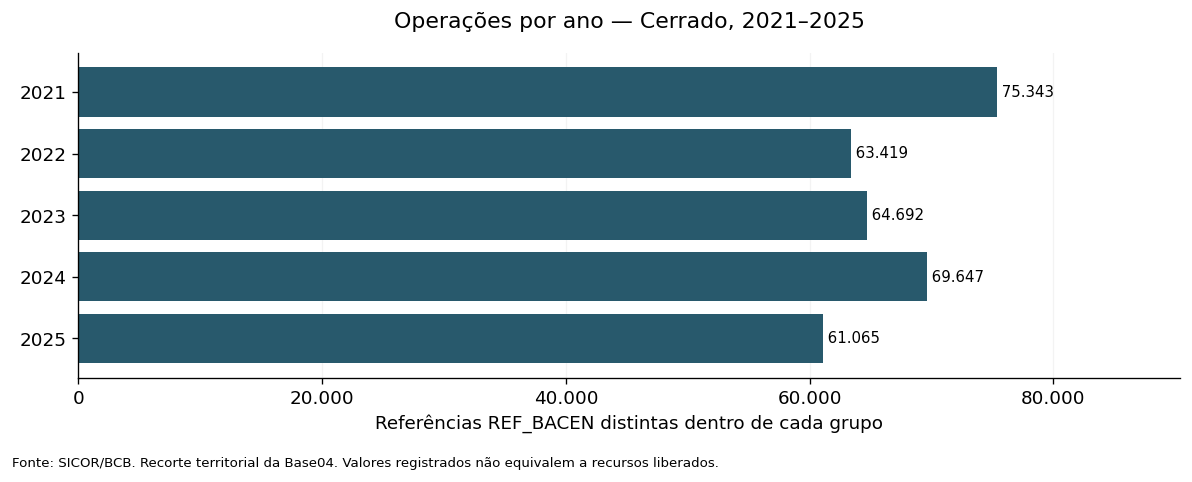

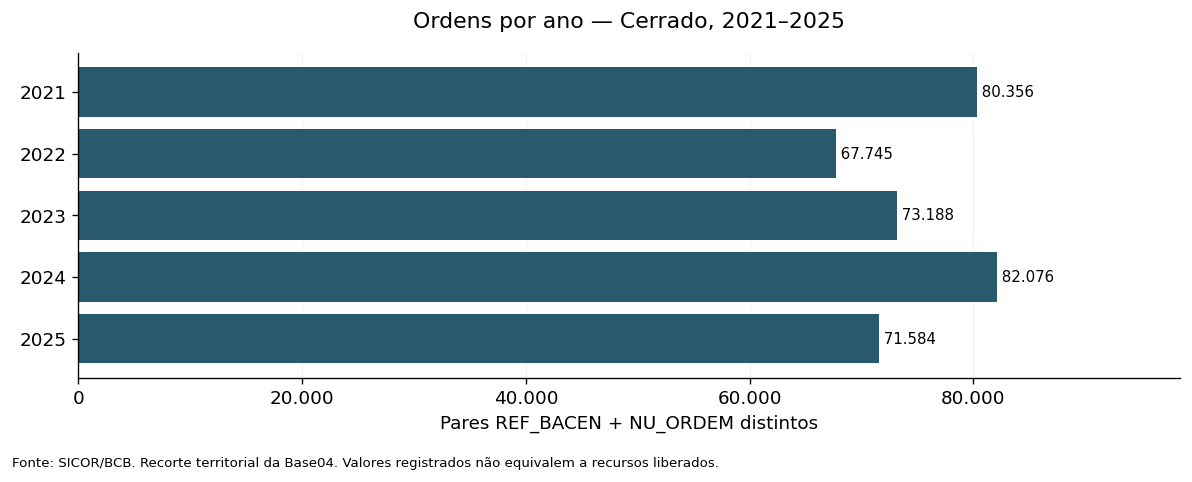

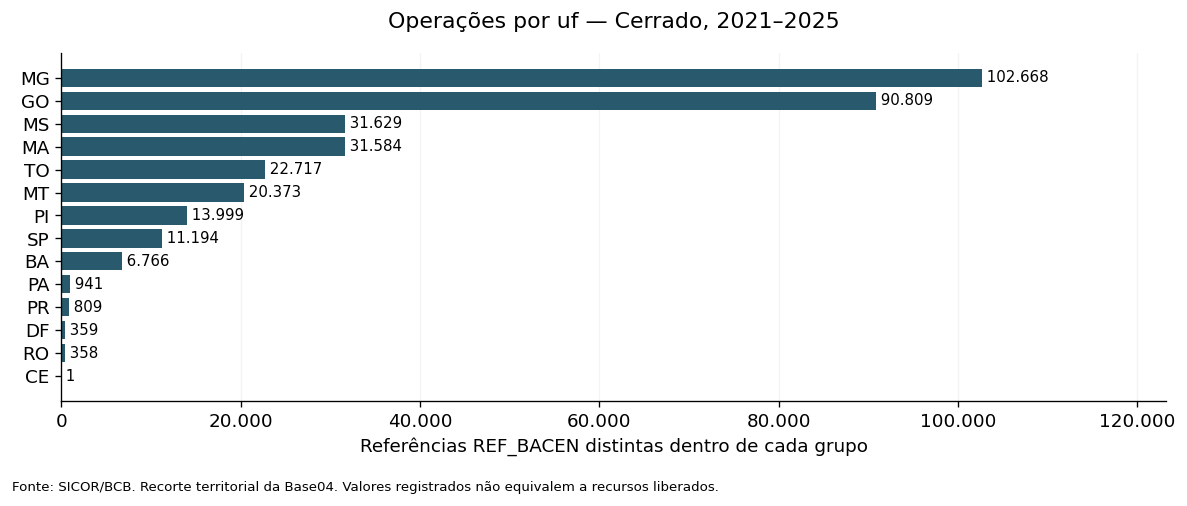

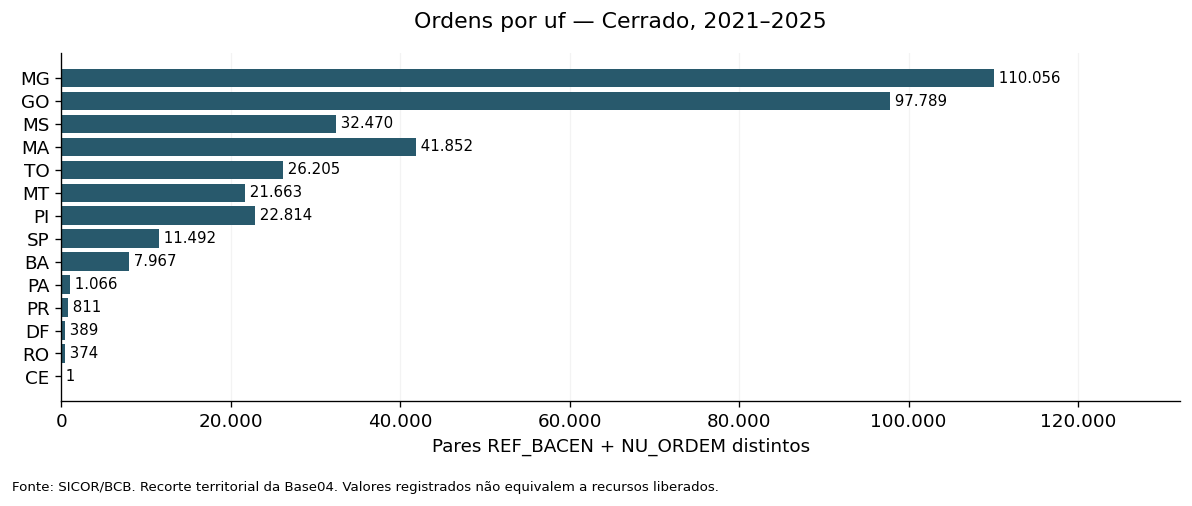

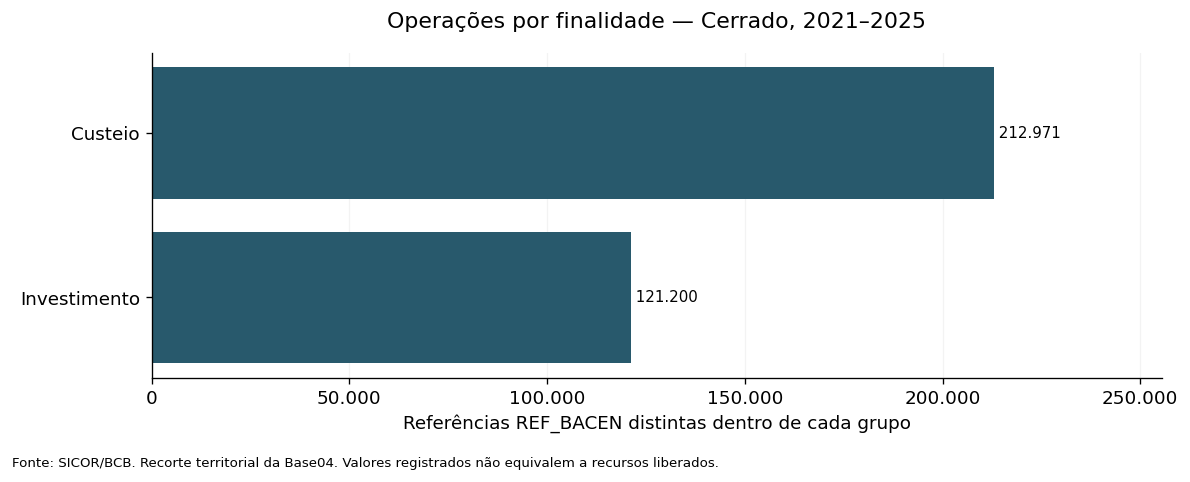

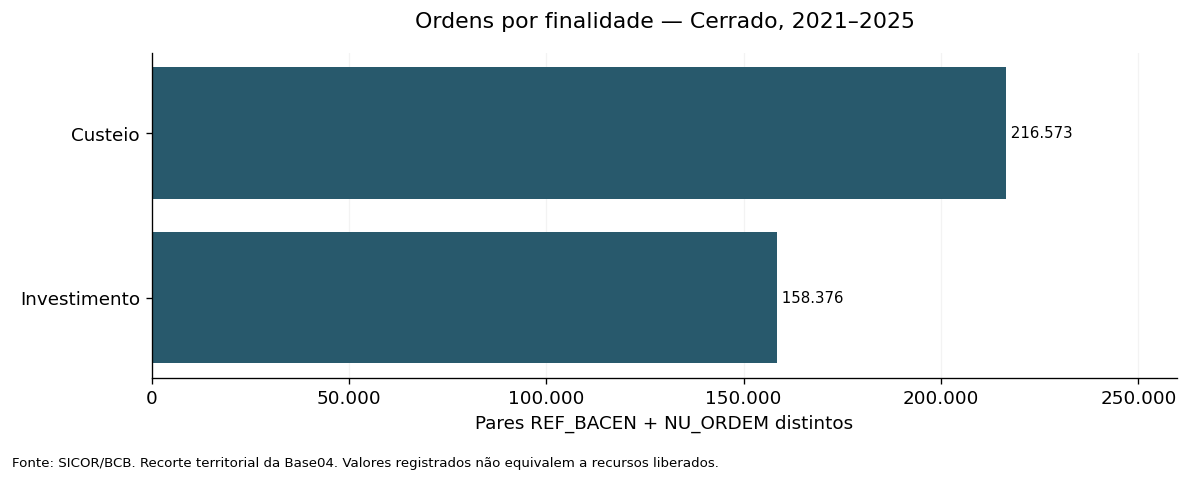

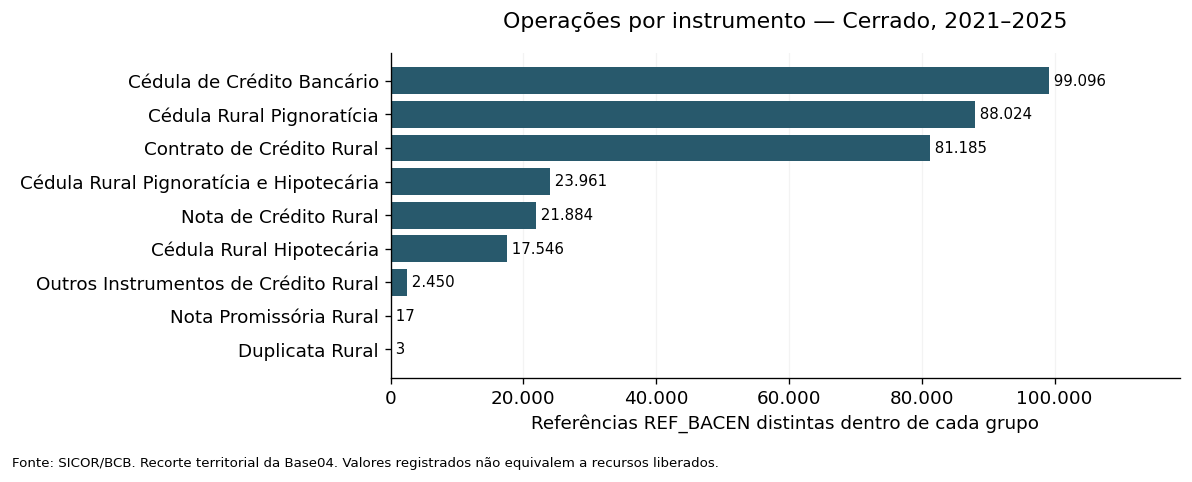

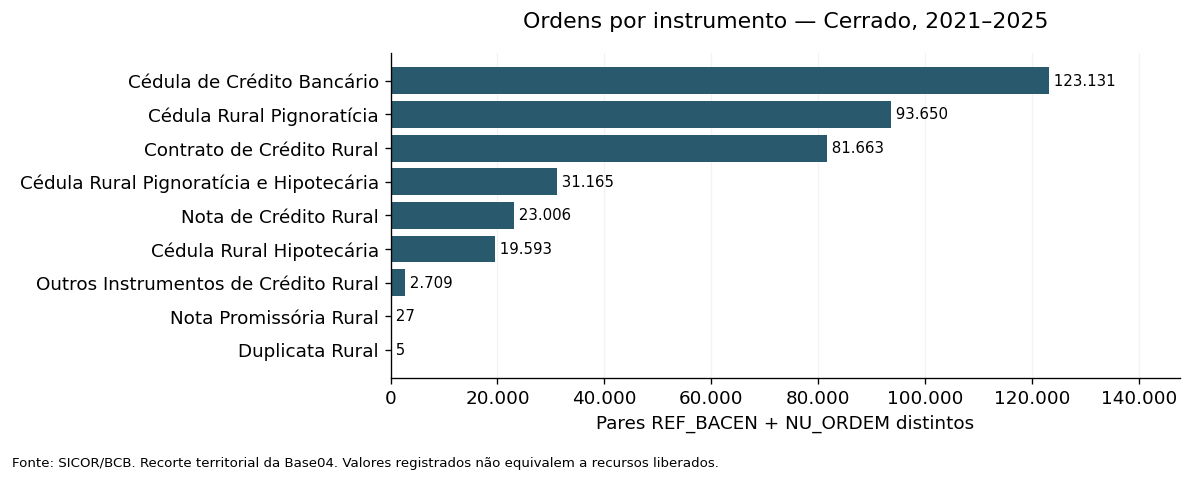

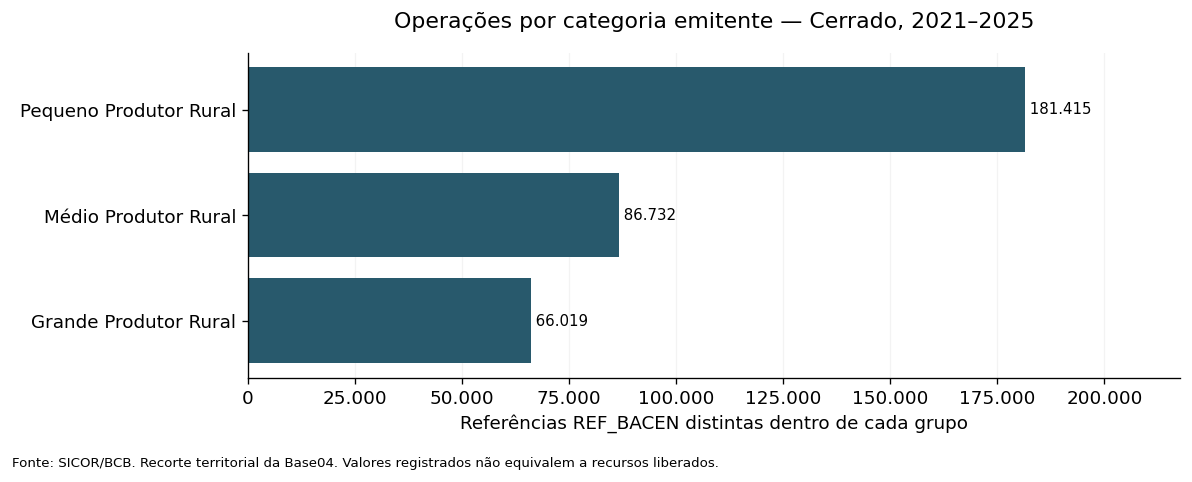

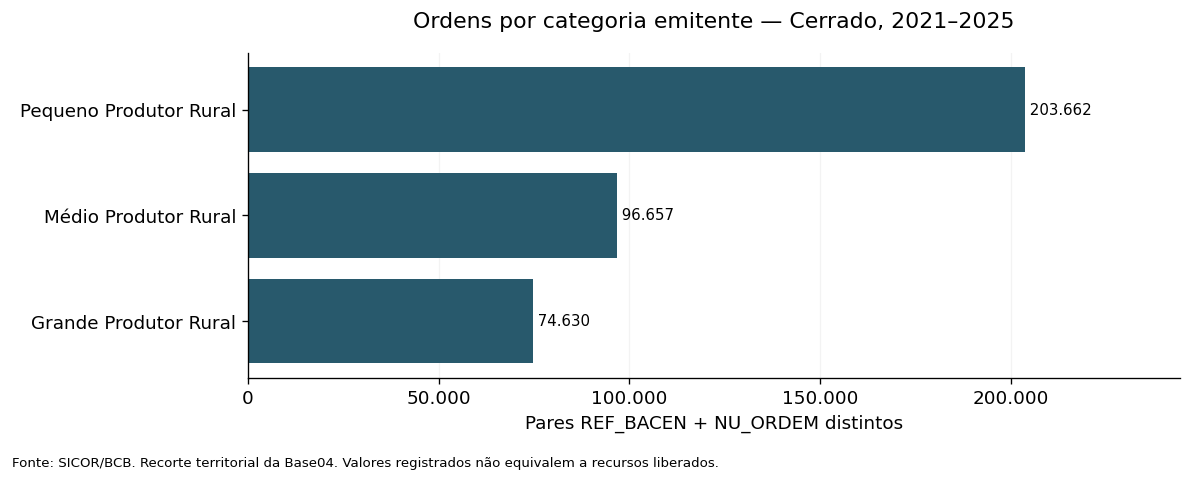

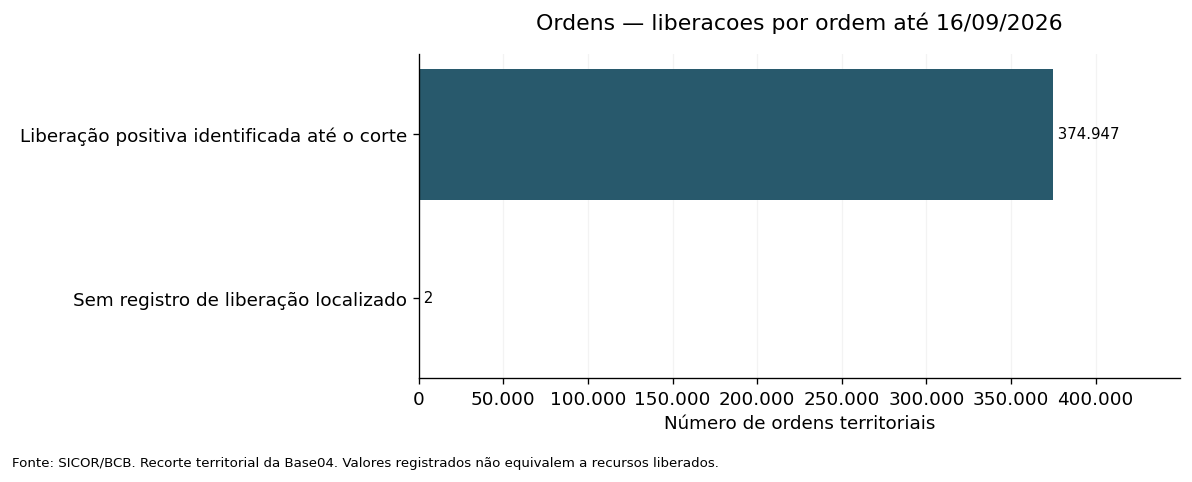

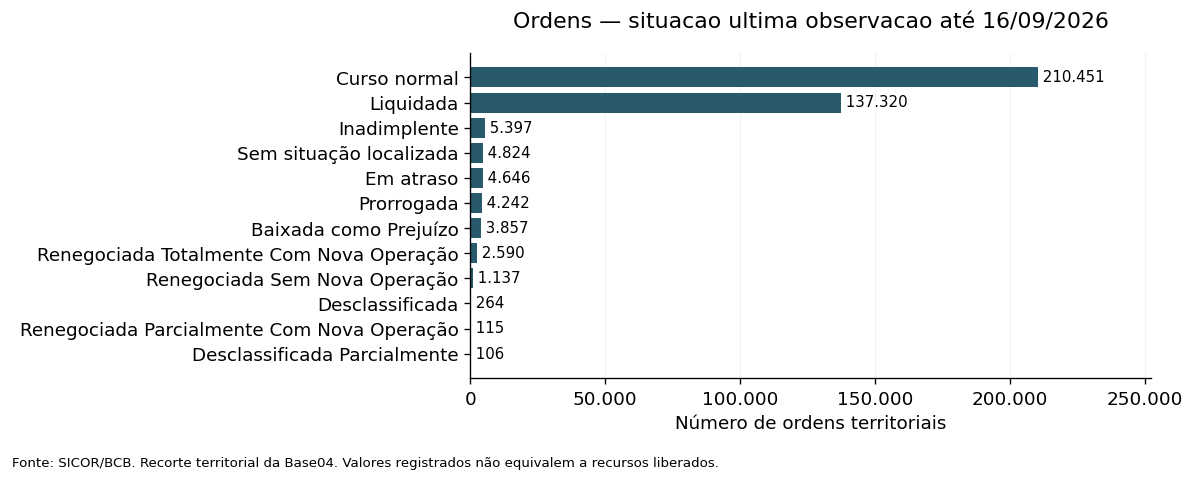

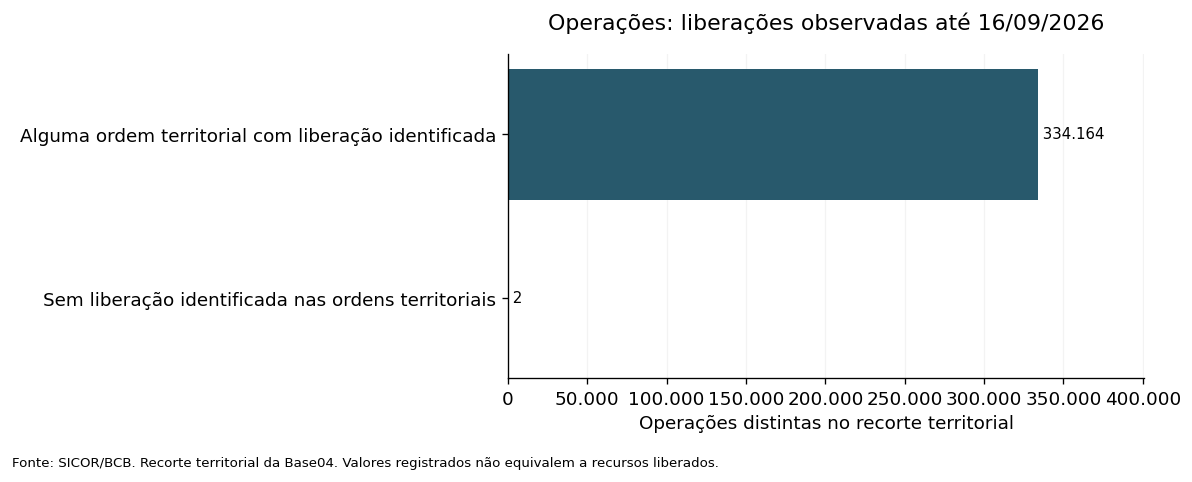

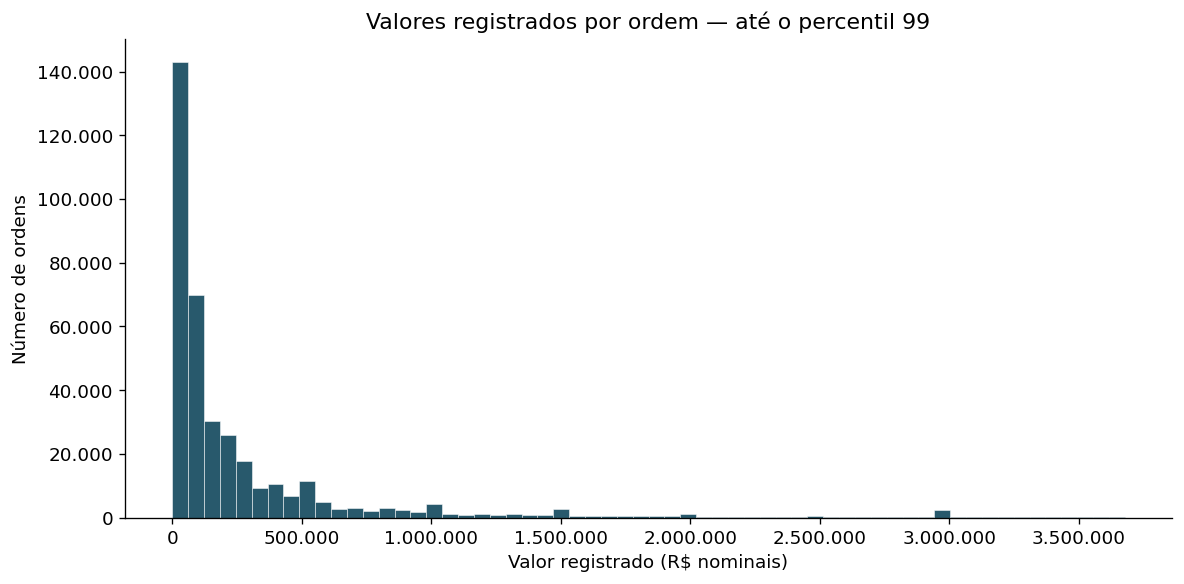

CONCLUÍDO
Pasta: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/Base04_enriquecimento_detalhado/correcao_uf_finalidade_financeiro/20260917_020231_695319
Base completa: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/Base04_enriquecimento_detalhado/correcao_uf_finalidade_financeiro/20260917_020231_695319/sicor_cerrado_2021_2025_corrigido_financeiro.csv.gz
Tabela para somar valores: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/Base04_enriquecimento_detalhado/correcao_uf_finalidade_financeiro/20260917_020231_695319/ordens_corrigidas_financeiro.csv
Pacote de revisão: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/Base04_enriquecimento_detalhado/correcao_uf_finalidade_financeiro/20260917_020231_695319/resumo_graficos.zip


,INDICADOR,TOTAL
0,registros_territoriais,480679
1,operacoes_distintas,334166
2,ordens_territoriais,374949
3,geometrias_distintas,395575
4,ordens_sem_uf,0
5,ordens_sem_finalidade,0
6,ordens_com_liberacao_positiva,374947
7,operacoes_com_alguma_ordem_territorial_liberada,334164
8,ordens_liquidadas_ultima_observacao,137320
9,ordens_liquidadas_mes_corte,0


Antes de usar o texto: leia LEIA_RESULTADOS.md e auditoria_leitura_cobertura.csv.


In [16]:
resumo = graficos(base_final,ordens_financeiras,operacoes_financeiras,SAIDA,CORTE)
# Pacote compacto para compartilhar. Não duplica as bases grandes nem o banco SQLite.
zip_path=SAIDA/'resumo_graficos.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SAIDA.rglob('*')):
        if p.is_file() and p!=zip_path and p.suffix in {'.csv','.md','.json','.png','.pdf'} and p.stat().st_size<20_000_000:
            z.write(p,p.relative_to(SAIDA))
print('CONCLUÍDO')
print('Pasta:',SAIDA)
print('Base completa:',SAIDA/'sicor_cerrado_2021_2025_corrigido_financeiro.csv.gz')
print('Tabela para somar valores:',SAIDA/'ordens_corrigidas_financeiro.csv')
print('Pacote de revisão:',zip_path)
display(pd.DataFrame(resumo.items(),columns=['INDICADOR','TOTAL']))
print('Antes de usar o texto: leia LEIA_RESULTADOS.md e auditoria_leitura_cobertura.csv.')
